In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

In [11]:
# Load and inspect the dataset
df = pd.read_csv('E commerce data set.csv',encoding='latin1')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010 08:26,3.39,17850.0,United Kingdom


In [12]:
df.shape

(541909, 8)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.6 MB


In [14]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [15]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [16]:
df.isnull().sum()


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [18]:
df = df.dropna(subset=['CustomerID'])

In [20]:
df = df.drop_duplicates()

In [24]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'],format = 'mixed',dayfirst=False,errors='coerce')

In [27]:
df = df[
    (df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [30]:
df['TotalAmount']=(
    df['Quantity'] * df['UnitPrice']
 )

In [ ]:
# calculate customer purchasing information
print("Total Customers:",df['CustomerID'].nunique())

print("Average Purchase Value:",df['TotalAmount'].mean())

print("Total Revenue:",df['TotalAmount'].sum())




Total Customers: 4338
Average Purchase Value: 22.631499735161402
Total Revenue: 8887208.894000001


In [34]:
#calculate purchase frequency
frequency = df.groupby('CustomerID')['InvoiceDate'].nunique()
print(frequency.describe())

count    4338.000000
mean        4.250807
std         7.635202
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       210.000000
Name: InvoiceDate, dtype: float64


In [35]:
#calculate rececy
reference_date = df['InvoiceDate'].max()+pd.Timedelta(days=1)
recency= df.groupby('CustomerID')['InvoiceDate'].max()
recency = (reference_date - recency).dt.days



In [36]:
#calculate frequency
frequency = df.groupby('CustomerID')['InvoiceDate'].nunique()

In [37]:
#calculate monetary
monetary= df.groupby('CustomerID')['TotalAmount'].sum()

In [39]:
rfm = pd.DataFrame({
    'Recency': recency,
    'Frequency':frequency,
    'Monetary': monetary
})
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [40]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.250807,2048.688081
std,100.014169,7.635202,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,210.000000,280206.020000


In [44]:
scaler= StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency','Frequency','Monetary'],
    index = rfm.index
 )
rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425815,8.363010
12347.0,-0.905340,0.360110,0.251699
12348.0,-0.175360,-0.032853,-0.027988
12349.0,-0.735345,-0.425815,-0.032406
12350.0,2.174578,-0.425815,-0.190812


In [46]:
wcss = []
for k in range(1,11):
     kmeans= KMeans(
           n_clusters= k,
           random_state=42,
           n_init=10
     )


     kmeans.fit(rfm_scaled)
     wcss.append(kmeans.inertia_)

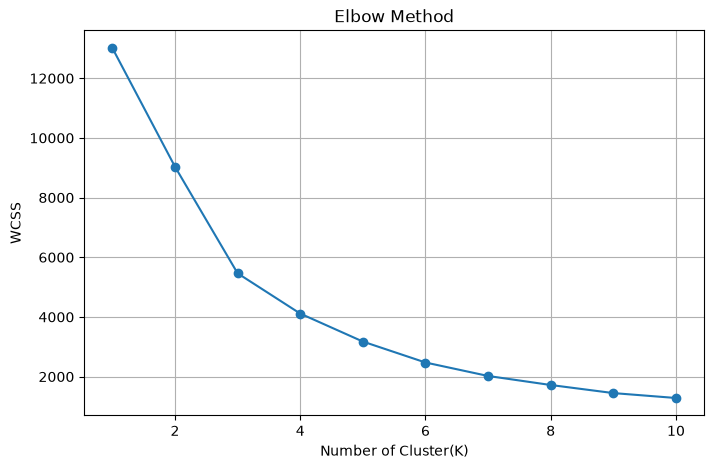

In [48]:
plt.figure(figsize=(8,5))
plt.plot(
    range(1,11),
    wcss,
    marker='o'
)
plt.title('Elbow Method')
plt.xlabel('Number of Cluster(K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [51]:
#Apply  K-Means Clustering
kmeans= KMeans(
 n_clusters=4,
 random_state=42,
 n_init=10
)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
rfm.head()


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,0
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,1
12350.0,310,1,334.40,3


In [52]:
print(rfm['Cluster'].value_counts())

Cluster
1    3053
3    1062
0     210
2      13
Name: count, dtype: int64


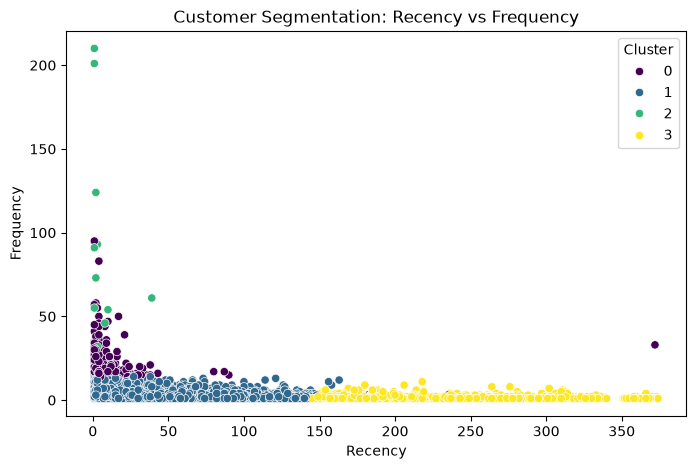

In [69]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis'

)
plt.title('Customer Segmentation: Recency vs Frequency')
plt.show()

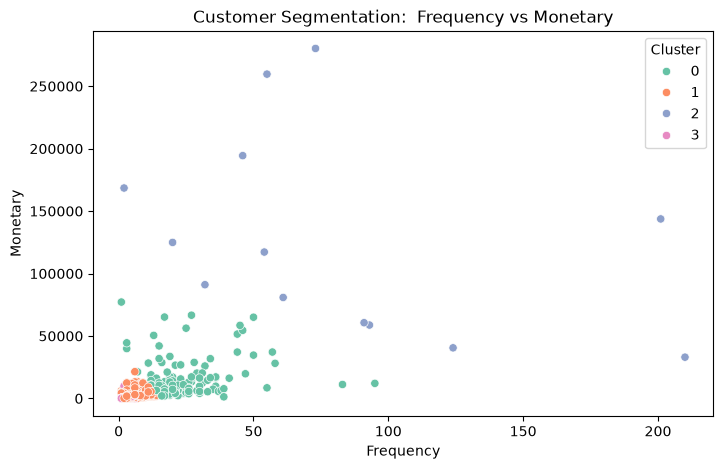

In [70]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2'
)
plt.title('Customer Segmentation:  Frequency vs Monetary')
plt.show()

In [71]:
cluster_profile = rfm.groupby('Cluster')[
     ['Recency','Frequency','Monetary']
].mean()

print(cluster_profile)

            Recency  Frequency       Monetary
Cluster                                      
0         15.371429  21.861905   12425.436905
1         43.931870   3.648542    1349.020843
2          7.384615  81.692308  127187.959231
3        248.564030   1.551789     476.330547


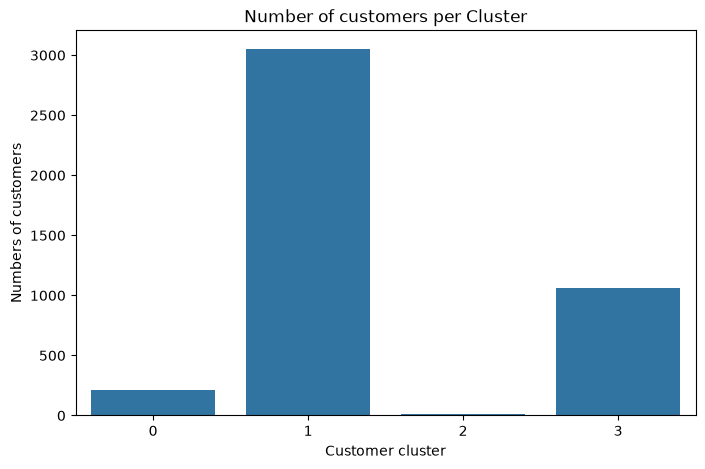

In [74]:
cluster_counts = rfm['Cluster'].value_counts().sort_index()
plt.figure(figsize=(8,5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)
plt.title('Number of customers per Cluster')
plt.xlabel('Customer cluster')
plt.ylabel('Numbers of customers')
plt.show()

BUISNESS INSIGHTS AND MARKETING RECOMMENDATIONS

The RFM-based K-Means clustering analysis identified four distinct customer segments based on purchasing behaviour, purchase frequency, and monetary value.

Key Business Insights:

1. VIP Customers (Cluster 2): These customers have the highest purchase frequency and monetary value. They represent the most valuable customer segment and should receive personalized services and exclusive benefits.
2. Loyal Customers (Cluster 0): These customers purchase frequently and demonstrate strong engagement. Loyalty programs and reward-based marketing can help retain them.
3. Regular Customers (Cluster 1): This is the largest customer segment. Although their average spending and purchase frequency are relatively low, they offer significant opportunities for business growth through discounts, combo offers, and cross-selling.
4. At-Risk Customers (Cluster 3): These customers have not purchased for a long time and have low purchasing activity. Targeted reactivation campaigns can help improve customer retention.

Marketing Recommendations:

- Introduce VIP membership and personalized rewards for high-value customers.
- Develop loyalty programs to retain regular and loyal customers.
- Provide attractive discounts and product bundles to increase purchase frequency.
- Launch targeted email and promotional campaigns to reactivate inactive customers.
- Use customer purchasing patterns to develop personalized marketing strategies.

Overall Conclusion:

Customer segmentation helps businesses understand different customer behaviours and develop targeted marketing strategies. By focusing on customer retention, personalized promotions, and customer reactivation, businesses can improve customer satisfaction, increase customer lifetime value, and maximize long-term revenue growth.